In [1]:
import numpy as np
import matplotlib.pyplot as plt

from bayesian_network import BayesNet, Variable
from utils import sample_categorical, get_default_bayes_net

In [2]:
# Reuse the topological iterator and LW initializer without executing another notebook.
from typing import Iterator

def __iter__(self) -> Iterator[Variable]:
    """
    Iterates over all variables in the Bayesian network in topological ordering, i.e.,
    for an edge from a variable X to a variable Y, X is returned before Y.  
    Since a Bayesian network is a directed acyclic graph, a topological ordering can always be found. 

    :yields: variable after variable according to the network's topology.
    """
    
    # list of topologically sorted variables to be returned
    sorted_variables = list()  
    # all variables in the network encoded as a dictionary (keys: variable ids, values: Variable objects)
    variables = self.nodes  
    
    def __topological_sort__(var: Variable):
        # mark node as visited
        visited.add(var)
        for ch_var_idx in var.children:
            ch_var = variables[ch_var_idx]
            # check if child variable has been visited before
            if not ch_var in visited:
                # if not yet visited, recursive depth-first traversal from child node 
                __topological_sort__(ch_var)
        # we add the current node after all descendents have been added
        sorted_variables.append(var)
    
    # set to store already visited nodes
    visited = set()
    # iterate over all variables in the network (can be any order!)
    for var_idx in variables:
        var = variables[var_idx]
        if not var in visited:
            # start recursive depth-first traversal from current node
            __topological_sort__(var)
    
    # reverse list to get the topological ordering
    sorted_variables = sorted_variables[::-1]

    for node in sorted_variables:
        yield node

# bind the implemented iterator method to the BayesNet
BayesNet.__iter__ = __iter__

def sample_lw(bayes_net: BayesNet, sample_size: int, evidence: dict={}):
    '''
    Samples from the mutilated network.
    :param bayes_net: A Bayesian network of type BayesNet.
    :param sample_size: The number of samples to draw from the Bayesian network.
    :param evidence: A dictionary of evidence variables (keys, int) and their correponding values (values, int).
    :returns: A NumPy array of type np.int64 with shape (sample_size, len(bayes_net)),
              and a NumPy array of shape (sample_size,) with the corresponding weight for each sample.
    '''
    
    # arrays holding the samples and the weights
    samples = np.empty((sample_size, len(bayes_net)), np.int64)
    weights = np.ones(sample_size)
    

    # process parents before children so each conditional is fully specified.
    variables = list(bayes_net)

    # iterate over all samples
    for i in range(sample_size):

        # iterate over all variables in the network
        for variable in variables:

            # get the conditional distribution of the variable given its parents
            distribution = variable(samples[i])

            # check if the variable is in the evidence
            if variable.id in evidence:
                # Clamp evidence and accumulate its likelihood
                value = evidence[variable.id]
                samples[i, variable.id] = value
                weights[i] *= distribution[value]
            else:
                # Sample from the conditional distribution and store the result
                samples[i, variable.id] = sample_categorical(distribution)
    
    return samples, weights

# Gibbs Sampling (Bonus)

<div class="alert alert-warning">
Implement the Gibbs sampling algorithm.
</div>

In Gibbs sampling, we sample directly from the target distribution $P_{\mathcal{B}}( \mathbf{Y} \mid \mathbf{E}=\mathbf{e})$ ($\mathbf{Y}$ denotes the set of non-evidence variables). We do this by implicitly constructing a sequence of proposal distributions that converge to the target distribution.

## Implementation

Implement
- `resampling_distribution`,
- `sample_gibbs`, and
- `gibbs_sampling`.

`resampling_distribution` computes the re-sampling distribution for a given variable.

`sample_gibbs` samples a sequence of random events according to all the relevant re-sampling distributions. 

`gibbs_sampling` approximates $P( X \mid \mathbf{E}=\mathbf{e})$ from a sequence of random events. Again, we will only consider probabilistic queries with one query variable $X$.

### Pre-computing the Re-sampling Distribution


Before we implement the Gibbs sampling algorithm, let us first write a helper function, which pre-computes the re-sampling distribution $P(X \mid mb(X))$ for an arbitrary variable $X$ in a given Bayesian Network.

Consider the following Bayesian network:

<img width='30%' src='img/bn.svg'>

To pre-compute $P(B \mid mb(B)) = P(B \mid A, C, D)$, we only need the conditional distribution of the $B$ and all of B's children, i.e., $P(B \mid A)$ and $P(D \mid B, C)$


<img width='30%' src='img/mb.png'>


The re-sampling distribution of $B$ can then be computed as follows: $P(B \mid A, C, D) = \frac{P(B \mid A) \cdot P(D \mid B, C)}{\sum_{b \in val(B)} P(B=b \mid A) \cdot P(D \mid B=b, C)}$

As an example, let's compute the re-sampling distribution for $B$ with NumPy. First, let us create the bayes net:

In [3]:
# initialize the Bayes net
_A_, _B_, _C_, _D_, _E_ = 0, 1, 2, 3, 4

A = np.array([0.2, 0.8])
B_A = np.array([[0.9, 0.2], [0.1, 0.8]])
C = np.array([0.9, 0.1])
D_BC = np.array([[[0.1, 0.2], [0.99, 0.8]], [[0.9, 0.8], [0.01, 0.2]]])
E_C = np.array([[0.7, 0.4], [0.3, 0.6]])
            
bayes_net = BayesNet(
    (A, [_A_]),
    (B_A, [_B_, _A_]),
    (C, [_C_]),
    (D_BC, [_D_, _B_, _C_]),
    (E_C, [_E_, _C_])
)

We can use the (conditional) probability distribution table of each variable (`variable.pdt`) to compute the re-sampling distribution. Note that the axes of `variable.pdt` are sorted by the variables's IDs and singleton dimensions are inserted for non-parent variables. This will make computations easier because we don't have to swap dimensions or insert empty dimensions for broadcasting:

In [4]:
print('Shape of P(B | A):    ', bayes_net[_B_].pdt.shape)
print('Shape of P(D | B, C): ', bayes_net[_D_].pdt.shape)

Shape of P(B | A):     (2, 2, 1, 1, 1)
Shape of P(D | B, C):  (1, 2, 2, 2, 1)


Computing $P(B \mid A, C, D) = \frac{P(B \mid A) \cdot P(D \mid B, C)}{\sum_{b \in val(B)} P(B=b \mid A) \cdot P(D \mid B=b, C)}$ is then easy:

In [5]:
# compute the rdt
rdt = bayes_net[_B_].pdt * bayes_net[_D_].pdt 
rdt = rdt / rdt.sum(axis=_B_, keepdims=True)

print(rdt.shape)

(2, 2, 2, 2, 1)


The dimensions of the re-sampling distribution table are also sorted by variable id, and singleton dimensions of size 1 are inserted for non-Markov-blanket variables. This is also the expected output format of the *resampling_distribution* function.

## 2.1. Pre-computing All the Re-sampling Distributions

The `BayesNet` class has an optional constructor argument that have not used so far. This argument takes a function that computes the re-sampling distribution for a given variable. If this is provided, the `BayesNet` will use it to pre-compute re-sampling distribution tables for all its variables upon construction. These will become useful when we implement Gibbs sampling.

<div class="alert alert-warning">
    Implement the <i>resampling_distribution</i> function, which computes the re-sampling distribution for a given variable.
</div>

`resampling_distribution` takes two parameters:
- `variable` is a `Variable` object for which the re-sampling distribution is to be computed.
- `bayes_net` is a `BayesNet` object which holds the (conditional) probability distribution table of each variable.

`resampling_distribution` returns a tuple containing two objects:
- a `np.ndarray` containing the re-sampling distribution $P(X \mid \textit{mb}(X))$ of the variable. The dimensions of the re-sampling distribution table must be sorted by variable id, and singleton dimensions of size 1 must be inserted for non-Markov-blanket variables.
- a `set` containing the IDs of all variables in $\textit{mb}(X)$. 

Hints:
 - `variable.parents` and `variable.children` will give you the ids of all parent and child variables, respectively.
 - `bayes_net[i]` returns the variable object with id `i`
 - `variable.pdt` gives the conditional probability distribution table of variable given its parents. The axis of this table are sorted by variable id, and singleton dimensions of size 1 are inserted for parent variables.
 - use `mb.add` or `mb.union` to add new variables to the `set`
 - use `mb.remove` or `mb.difference` to remove variables from the `set`

In [6]:
def resampling_distribution(variable: Variable, bayes_net: BayesNet):
    '''
    Computes the resampling distribution given a variable and a Bayesian network.
    :param variable: The variable for which to compute the resampling distribution.
    :param bayes_net: A Bayesian network of type BayesNet. The bayes net is used to obtain the
                      probability table from child variables.
    :returns: A tuple containing the resampling distribution ('rdt') and a list containing
              the IDs of variables in the Markov blanket ('mb').
    '''
    
    rdt, mb = None, None
    
    # The only joint-distribution factors involving this node are its
    # own conditional table and the conditional tables of its children.
    rdt = variable.pdt.copy()
    mb = set(variable.parents)
    for child_id in variable.children:
        child = bayes_net[child_id]
        rdt = rdt * child.pdt
        mb.add(child_id)
        mb.update(child.parents)
    mb.discard(variable.id)

    normalizer = rdt.sum(axis=variable.id, keepdims=True)
    # Impossible blanket assignments have no defined conditional distribution.
    rdt = np.divide(rdt, normalizer, out=np.zeros_like(rdt), where=normalizer > 0)
    
    assert rdt.ndim == len(bayes_net)
    assert variable.id not in mb
    assert type(mb) is set
    
    return rdt, mb

In [7]:
import traceback
any_failed = False
try:
    # get_default_bayes_net returns the same Bayes net as defined above; just in case the variable was modified...
    bayes_net = get_default_bayes_net()
    
    # compute resampling distribution table of P( B | mb(B) ); same as above 
    rdt = bayes_net[_D_].pdt * bayes_net[_B_].pdt
    rdt = rdt / rdt.sum(axis=_B_, keepdims=True)
    # set containing all the indices of the variables in mb(B)
    mb = {_A_, _D_, _C_}
    
    expected = rdt, mb
    actual = resampling_distribution(bayes_net[_B_], bayes_net)
    
    #sanity checks
    assert type(actual[1]) == type(expected[1]), f'Set of parents has wrong data type.\n Expected: {type(expected[1])}\nGiven: {type(actual[1])}'
    assert actual[1] == expected[1], f'The variables in the Markov blanket are not correct.\n Expected: {expected[1]}\nGiven: {actual[1]}'
    
    assert expected[0].shape == actual[0].shape, f'Resampling distribution has the wrong shape!\nExpected: {expected[0].shape}\nGiven:\t  {actual[0].shape}'
    assert expected[0].dtype == actual[0].dtype, f'Wrong numpy array data type!\nExpected: {expected[0].dtype}\nGiven:\t  {actual[0].dtype}'
    assert np.all(np.isclose(8, actual[0].sum())), f'Incorrect normalization. Sum of CPDT is: {actual[0].sum()}'
    assert np.all(np.isclose(expected[0], actual[0])), f'Computation of resampling distribution did not yield the correct result.'

except Exception as e:
    print("Error:", e)
    traceback.print_exception(type(e), e, e.__traceback__)
    any_failed = True

assert not any_failed, "See error message above..."

### 2.2. Gibbs Sampling

<div class="alert alert-warning">
Implement the <i>sample_gibbs</i> function.
</div>

`sample_gibbs` takes five parameters:
- `bayes_net` is a `BayesNet` object to draw samples from (it uses your `resampling_distribution()` from above).
- `sample_size` is the number of samples to use for the estimation.
- `evidence` is a dictionary of variable_ids (keys) and values (values) assigned to the variable. (optional, default = {})
- `burn_in_samples` gives the number of burn-in steps to take (>= 0). (optional, default = 0)
- `sample_distance` gives the number of steps to take to get the next sample (> 0). (optional, default = 1)

`sample_gibbs` function must return one object:
- samples from $P_{\mathcal{B}}( \mathbf{Y} \mid \mathbf{E}=\mathbf{e})$ of type `np.ndarray`, with shape `(sample_size, len(bayes_net))`


Initialize the Markov chain with a random event drawn from $\mathcal{B}_{\mathbf{E}=\mathbf{e}}$. The first element in the sample is the random event obtained after performing a total of `burn_in_samples` steps. Thereafter, perform `sample_distance` steps to obtain each one of the next `sample_size` samples. Hence, `burn_in_samples + (sample_size - 1) * sample_distance` steps will be performed in total.

To make your implementation comparable to ours, sample the new values for the non-evidence variables in the topological order provided by the BayesNet class, i.e. `for variable in bayes_net: ...`.


**Hint**:
- `sample_lw(bayes_net, 1, evidence=evidence)[0]` draws an initial sample from $\mathcal{B}_{\mathbf{E}=\mathbf{e}}$
- the pre-computation of the re-sampling distributions is handled by the BayesNet (we pass your `resampling_distribution` function to the BayesNet object at instantiation time)
- to obtain the distribution $P(X \mid \mathit{mb}(X))$, simply call `variable(sample, resampling=True)`; this uses the precomputed re-sampling distribution instead of `variable.pdt`, and is only available because we passed `resampling_distribution` to the BayesNet constructor
- it may help to define a function that performs $n$ Gibbs steps on a sample, and reuse it &mdash; you can even define a local function in the middle of `sample_gibbs()`! mind that Python arguments are passed by reference, use `.copy()` on an `ndarray` if needed.


In [8]:
def sample_gibbs(bayes_net: BayesNet, sample_size: int, evidence: dict={}, burn_in_samples: int=0, 
                 sample_distance: int=1):
    '''
    Returns sample_size samples from the target distribution P( Y | E=e ).
    :param bayes_net: A Bayesian network of type BayesNet.
    :param sample_size: The number of samples to use for the estimation.
    :param evidence: A dictionary of evidence variables (keys, int) and their correponding values (values, int).
    :param burn_in_samples: The number of burn-in samples to throw away (>= 0).
    :param sample_distance: Use only every n-th sample. (> 0)
    :returns: A NumPy array of type np.int64 with shape (sample_size, len(bayes_net)).
    '''
    
    assert burn_in_samples >= 0
    assert sample_distance > 0
    
    samples = np.empty((sample_size, len(bayes_net)), np.int64)
    
    # the initial sample to start the Markov chain with
    sample = sample_lw(bayes_net, 1, evidence=evidence)[0][0].copy()
    
    # A step is a full sweep, updating all non-evidence nodes in order.
    nodes = [node for node in bayes_net if node.id not in evidence]

    def advance(num_steps):
        for _ in range(num_steps):
            for node in nodes:
                distribution = node(sample, resampling=True)
                if distribution.sum() == 0:
                    raise ValueError("Cannot resample an impossible Markov blanket assignment.")
                sample[node.id] = sample_categorical(distribution)

    advance(burn_in_samples)
    for i in range(sample_size):
        if i > 0:
            advance(sample_distance)
        # Assignment copies the state into a separate row of the output array.
        samples[i] = sample
        
    return samples

In [9]:
any_failed = False
try:
    # get_default_bayes_net returns the same Bayes net as defined above; just in case the variable was modified...
    # this time we also pass the function to pre-compute the resampling distributions
    bayes_net = get_default_bayes_net(resampling_distribution=resampling_distribution)
    print([v.id for v in bayes_net])
    np.random.seed(0)
    expected = np.array([[0, 0, 0, 1, 0], [0, 0, 0, 0, 0], [0, 0, 1, 0, 0],
                         [0, 0, 0, 0, 0], [0, 0, 0, 1, 0], [0, 0, 0, 1, 1]], dtype=np.int64)
    actual = sample_gibbs(bayes_net, 6, {0:0}, 7, 3)
    
    # sanity checks
    assert type(actual) == type(expected), f'\nWrong output type!\nExpected: {type(expected)}\nGiven:\t  {type(actual)}'
    assert actual.shape == expected.shape, f'\nWrong output shape!\nExpected: {expected.shape}\nGiven:\t  {actual.shape}'
    assert actual.dtype == expected.dtype, f'\nWrong numpy array data type!\nExpected: {expected.dtype}\nGiven:\t  {actual.dtype}'
    assert np.all(np.isclose(actual, expected)), f'samples and reference samples do not match.\nExpected:\n{expected}\n\nGiven:\n{actual}\n\nIf your last two samples are the same, this may hint at a bug.'

except Exception as e:
    print("Error:", e)
    traceback.print_exception(type(e), e, e.__traceback__)
    any_failed = True
    
assert not any_failed, "See error message above..."

[2, 4, 0, 1, 3]


<div class="alert alert-warning">
Implement the <i>gibbs_sampling</i> function to estimate the probability distribution over the query variable $X$ given the evidence $\mathbf{E}=\mathbf{e}$, $P(X \mid \mathbf{E}=\mathbf{e})$.
</div>

`gibbs_sampling` takes six parameters:
- `bayes_net` is a `BayesNet` object to draw samples from.
- `query_variable_id` is the id of the query variable (int).
- `evidence` is a dictionary of variable_ids (keys) and values (values) assigned to the variable. (optional, default = {})
- `sample_size` gives the number of samples to use for the estimation (optional, default = 100).
- `burn_in_samples` gives the number of burn-in samples to throw away (>= 0). (optional, default = 0)
- `sample_distance` gives the number of steps to take to get the next sample (> 0). (optional, default = 1)

`gibbs_sampling` function must return one object:
-  The probability distribution over variable $X$ of type `np.ndarray` with shape `(bayes_net[query_variable_id].num_values,)`.


**Hint**:
- use `np.bincount` to count the number of occurrences of each value; don't forget to set minlength
- the number of values a variable can take can be obtained via `variable.num_values`

In [10]:
def gibbs_sampling(bayes_net: BayesNet, query_variable_id: int, evidence: dict={}, 
                   sample_size: int=100, burn_in_samples: int=0, sample_distance: int=1):
    '''
    Estimates the distribution of the query variale given the value of the evidence variables.
    :param bayes_net: A Bayesian network of type BayesNet.
    :param query_variable_id: The id of the query variable (int).
    :param evidence: A dictionary of evidence variables (keys, int) and their correponding values (values, int).
    :param sample_size: The number of samples to use for the estimation.
    :burn_in_samples: The number of burn-in samples to throw away (>= 0).
    :param sample_distance: Use only every n-th sample. (> 0)
    :returns: A NumPy array of type np.float64 representing the conditional distribution of the query variable given evidence. 
    '''
    
    # draw samples...
    smpls = sample_gibbs(
        bayes_net, 
        sample_size, 
        evidence=evidence, 
        burn_in_samples=burn_in_samples, 
        sample_distance=sample_distance
    )
    
    if sample_size == 0:
        raise ValueError("At least one sample is required to estimate a distribution.")
    distribution = np.bincount(
        smpls[:, query_variable_id],
        minlength=bayes_net[query_variable_id].num_values,
    ) / sample_size
    
    return distribution

In [11]:
any_failed = False
try:
    # get_default_bayes_net returns the same Bayes net as defined above; just in case the variable was modified...
    # again, we also pass the function to pre-compute the resampling distributions
    bayes_net = get_default_bayes_net(resampling_distribution=resampling_distribution)
    
    np.random.seed(0)
    expected = np.array([0.25, 0.75], dtype=np.float64)
    actual = gibbs_sampling(bayes_net, 0, {2:1}, 100, 5, 3)
    
    # sanity checks
    assert type(actual) == type(expected), f'\nWrong output type!\nExpected: {type(expected)}\nGiven:\t  {type(actual)}'
    assert actual.shape == expected.shape, f'\nWrong output shape!\nExpected: {expected.shape}\nGiven:\t  {actual.shape}'
    assert actual.dtype == expected.dtype , f'\nWrong numpy array data type!\nExpected: {expected.dtype}\nGiven:\t  {actual.dtype}'
    assert np.all(np.isclose(1, actual.sum())), f'Incorrect normalization. Sum of PDT is: {actual.sum()}'
    assert  np.all(np.isclose(actual, expected)), f'Wrong output value.'

except Exception as e:
    print("Error:", e)
    traceback.print_exception(type(e), e, e.__traceback__)
    any_failed = True
    
assert not any_failed, "See error message above..."

## Example

Reconsider the Bayesian Network from the previous problems:

<img width='30%' src='img/bn_new.svg'>

The conditional probability tables are given as:

<table style="float: left;margin:5px;"><tr><th>P(A)</th><th>$a_0$<br></th><th>$a_1$</th></tr><tr><td>-</td><td>0.2</td><td>0.8</td></tr></table>

<table style="float: left;margin:5px;"><tr><th>P(B | A)</th><th>$a_0$<br></th><th>$a_1$</th></tr><tr><td>$b_0$</td><td>0.9</td><td>0.2</td></tr><tr><td>$b_1$</td><td>0.1</td><td>0.8</td></tr></table>

<table style="float: left;margin:5px;"><tr><th rowspan="2">P(D | A, B)</th><th colspan="2">$a_0$<br></th><th colspan="2">$a_1$</th></tr><tr><td>$b_0$</td><td>$b_1$</td><td>$b_0$</td><td>$b_1$</td></tr><tr><td>$d_0$<br></td><td>0.1</td><td>0.2</td><td>0.01</td><td>0.8</td></tr><tr><td>$d_1$</td><td>0.9</td><td>0.8</td><td>0.99</td><td>0.2</td></tr></table>

<table style="float: left;margin:5px;"><tr><th>P(C|D)</th><th>$d_0$<br></th><th>$d_1$</th></tr><tr><td>$c_0$</td><td>0.95</td><td>0.15</td></tr><tr><td>$c_1$</td><td>0.05</td><td>0.85</td></tr></table>

<table style="float: left;margin:5px;"><tr><th>P(E | C)</th><th>$c_0$</th><th>$c_1$</th></tr><tr><td>$e_0$</td><td>0.9</td><td>0.4</td></tr><tr><td>$e_1$</td><td>0.1</td><td>0.6</td></tr></table>

In [12]:
_A_, _B_, _C_, _D_, _E_ = 0, 1, 2, 3, 4

A = np.array([0.2, 0.8])
B_A = np.array([[0.9, 0.2], [0.1, 0.8]])
C_D = np.array([[0.95, 0.15], [0.05, 0.85]])
D_AB = np.array([[[0.1, 0.2], [0.01, 0.8]], [[0.9, 0.8], [0.99, 0.2]]])
E_C = np.array([[0.9, 0.4], [0.1, 0.6]])
              
bayes_net = BayesNet(
    (A, [_A_]),
    (B_A, [_B_, _A_]),
    (C_D, [_C_, _D_]),
    (D_AB, [_D_, _A_, _B_]),
    (E_C, [_E_, _C_]), resampling_distribution=resampling_distribution
)

### Exact Computation

In [13]:
A_DE = None

ABCDE = A[:, None, None, None, None] * B_A.T[:, :, None, None, None] * C_D [None, None, :, :, None] * D_AB.transpose(1, 2, 0)[:, :, None, :, None] * E_C.T[None, None, :, None, :]
ADE = ABCDE.sum(axis=(1, 2))
A_DE = ADE / ADE.sum(axis=0)[None, :, :]

### Comparison

Run the following code cell to plot the average [Kullback-Leibler divergence](https://en.wikipedia.org/wiki/Kullback%E2%80%93Leibler_divergence) between the exact distribution $P(A \mid D, E)$ and the approximations computed with Gibbs sampling. Different lines represent different value assignments to the evidence variables $D$ and $E$.

**Hint**: The computation of the approximations might take a while...

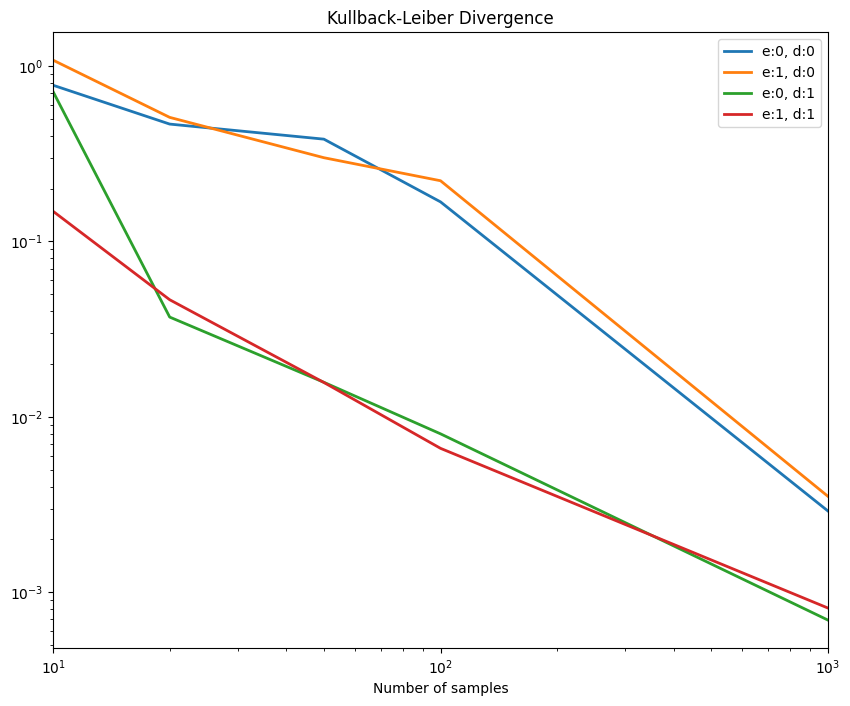

In [14]:
if __name__ == '__main__':
    from utils import approx_error
    
    np.random.seed(0)
    errs = {}
    sample_counts = np.array([10, 20, 50, 100, 1000])
    
    # compute approximation error
    for d, e in zip([0, 0, 1, 1], [0, 1, 0, 1]):
        errs[(d, e)] = approx_error(
            bayes_net,
            gibbs_sampling,  
            A_DE[:, d, e],
            _A_,
            {_D_:d, _E_:e}, 
            sample_counts,
            n_runs=100,
            burn_in_samples=0,
            sample_distance=1
        )
    
    # plot
    plt.figure(figsize=(10, 8))
    plt.title('Kullback-Leiber Divergence')
    for d, e in zip([0, 0, 1, 1], [0, 1, 0, 1]):
        plt.plot(sample_counts, errs[(d, e)], label=f'e:{e}, d:{d}', lw=2)
        
    plt.legend()
    plt.xscale('log')
    plt.yscale('log')
    plt.xlim(sample_counts.min(), sample_counts.max())
    plt.xlabel('Number of samples')
    plt.show()